In [18]:
import os, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture


RANDOM_STATE     = 42
DATA_FILE        = 'ftse2501_clustering_ready.csv'
MAX_MISSING_FRAC = 0.10
VARIANCE_TARGET  = 0.90
K_RANGE          = range(2, 9)
COV_TYPES        = ['spherical', 'diag', 'tied', 'full']
N_INIT           = 20
REG_COVAR_FRAC   = 0.01
N_SUBSAMPLES     = 100
SUBSAMPLE_FRAC   = 0.8

In [19]:
X_raw = pd.read_csv(DATA_FILE, index_col=0)
X_raw.columns = pd.to_datetime(X_raw.columns)

n_before = X_raw.shape[0]
frac_missing = X_raw.isna().sum(axis=1) / X_raw.shape[1]
tickers_dropped = frac_missing[frac_missing > MAX_MISSING_FRAC].index.tolist()

X_clean = X_raw.loc[frac_missing <= MAX_MISSING_FRAC].copy()
n_filled = int(X_clean.isna().sum().sum())
X_clean = X_clean.ffill(axis=1).bfill(axis=1)

print(f"Stocks before exclusion : {n_before}")
print(f"Dropped (>10% missing)  : {len(tickers_dropped)} {tickers_dropped}")
print(f"Gaps filled             : {n_filled}")
print(f"Stocks retained         : {X_clean.shape[0]}")
assert X_clean.isna().sum().sum() == 0, "Missing values remain after fill."

A = X_clean.values
print("Data matrix (stocks x days):", A.shape)

Stocks before exclusion : 250
Dropped (>10% missing)  : 2 ['PRN.L', 'SHAW.L']
Gaps filled             : 1
Stocks retained         : 248
Data matrix (stocks x days): (248, 273)


In [20]:
pca = PCA(n_components=VARIANCE_TARGET, random_state=RANDOM_STATE)
X = pca.fit_transform(A)
d = X.shape[1]


REG_COVAR = REG_COVAR_FRAC * X.var(axis=0).mean()

print(f"PCA: {A.shape[1]} days -> {d} components ({VARIANCE_TARGET:.0%} of variance)")
print("Variance explained per PC:", np.round(pca.explained_variance_ratio_ * 100, 1))
print(f"Clustering matrix: {X.shape}   (n = {X.shape[0]} stocks, d = {d})")
print(f"reg_covar = {REG_COVAR:.3f}  ({REG_COVAR_FRAC:.0%} of mean PC variance)")

PCA: 273 days -> 9 components (90% of variance)
Variance explained per PC: [50.  15.9  8.4  5.   4.3  2.6  1.8  1.5  1.2]
Clustering matrix: (248, 9)   (n = 248 stocks, d = 9)
reg_covar = 0.246  (1% of mean PC variance)


In [21]:
def make_gmm(k, cov, n_init=N_INIT, seed=RANDOM_STATE):
    return GaussianMixture(n_components=k, covariance_type=cov, n_init=n_init,
                           reg_covar=REG_COVAR, max_iter=500, random_state=seed)


_CM_CACHE = {}

def consensus_matrix(X, k, cov, B=N_SUBSAMPLES, frac=SUBSAMPLE_FRAC, n_init=5, seed=RANDOM_STATE):

    key = (X.shape, hash(X.tobytes()), k, cov, B, frac, n_init, seed, REG_COVAR)
    if key in _CM_CACHE:
        return _CM_CACHE[key]
    rng = np.random.default_rng(seed)
    n = X.shape[0]; m = int(frac * n)
    together = np.zeros((n, n)); sampled = np.zeros((n, n)); n_failed = 0
    for b in range(B):
        idx = rng.choice(n, m, replace=False)
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                lab = make_gmm(k, cov, n_init, seed + b).fit_predict(X[idx])
        except ValueError:
            n_failed += 1
            continue
        ix = np.ix_(idx, idx)
        together[ix] += (lab[:, None] == lab[None, :])
        sampled[ix] += 1
    if n_failed:
        print(f"  note: {n_failed}/{B} subsample fits failed for k={k}, '{cov}' (skipped)")
    M = np.divide(together, sampled, out=np.zeros((n, n)), where=sampled > 0)
    np.fill_diagonal(M, 1.0)
    _CM_CACHE[key] = M
    return M


def cluster_consensus(M, labels, n_clusters=None):

    labels = np.asarray(labels)
    ids = np.unique(labels) if n_clusters is None else range(n_clusters)
    out = []
    for c in ids:
        idx = np.where(labels == c)[0]
        if len(idx) < 2:
            out.append(np.nan); continue
        out.append(M[np.ix_(idx, idx)][np.triu_indices(len(idx), 1)].mean())
    return np.array(out)


def cdf_area(M):

    v = np.sort(M[np.triu_indices(M.shape[0], 1)])
    h = np.arange(1, len(v) + 1) / len(v)
    nxt = np.append(v[1:], 1.0)
    return float(np.sum(h * (nxt - v)))


def pac(M, lo=0.1, hi=0.9):

    v = M[np.triu_indices(M.shape[0], 1)]
    return float(np.mean((v > lo) & (v < hi)))


print("Helpers defined.")

Helpers defined.


In [22]:
rows = []
for cov in COV_TYPES:
    for k in K_RANGE:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            model = make_gmm(k, cov)
            model.fit(X)
        rows.append({
            'covariance_type': cov, 'k': k,
            'bic': model.bic(X),
            'log_likelihood': model.score(X) * X.shape[0],   # total log-likelihood
            'n_params': model._n_parameters(),
            'n_iter': int(model.n_iter_),
            'converged': bool(model.converged_),
        })
results_df = pd.DataFrame(rows)

# CHECK 2 (convergence): the EM log-likelihood must have converged
valid_df = results_df[results_df['converged']]
assert len(valid_df), "No fit converged - raise max_iter or REG_COVAR_FRAC."

# CHECK 1 (model complexity): lowest BIC among the converged fits
best_row = valid_df.loc[valid_df['bic'].idxmin()]
naive_row = results_df.loc[results_df['bic'].idxmin()]

print(f"Fits tried: {len(results_df)}   converged: {len(valid_df)}   not converged: {len(results_df) - len(valid_df)}")
print()
print(f"BIC-selected (converged only): k = {int(best_row['k'])}, '{best_row['covariance_type']}'  "
      f"(BIC {best_row['bic']:.0f}, log-likelihood {best_row['log_likelihood']:.0f})")
if int(best_row['k']) in (min(K_RANGE), max(K_RANGE)):
    print("WARNING: BIC optimum is at the edge of K_RANGE - widen the range or treat with caution.")
if not naive_row['converged']:
    print(f"\nWithout the convergence check BIC would have picked k = {int(naive_row['k'])}, "
          f"'{naive_row['covariance_type']}' (EM did not converge).")

print("\nTop 8 converged models by BIC:")
display(valid_df.sort_values('bic').head(8)[['covariance_type', 'k', 'bic', 'log_likelihood',
                                              'n_params', 'n_iter']].round(3).reset_index(drop=True))
print("Fits that did not converge:")
display(results_df[~results_df['converged']][['covariance_type', 'k', 'bic', 'log_likelihood', 'n_iter']]
        .round(0).reset_index(drop=True))

Fits tried: 28   converged: 28   not converged: 0

BIC-selected (converged only): k = 3, 'diag'  (BIC 11454, log-likelihood -5573)

Top 8 converged models by BIC:


,covariance_type,k,bic,log_likelihood,n_params,n_iter
0,diag,3,11454.127,-5572.688,56,20
1,diag,4,11462.310,-5524.401,75,28
2,diag,5,11519.904,-5500.821,94,29
3,diag,2,11539.791,-5667.897,37,16
4,diag,6,11579.015,-5477.999,113,24
5,diag,7,11616.669,-5444.448,132,28
6,diag,8,11678.626,-5423.049,151,37
7,full,2,11848.321,-5623.679,109,31


Fits that did not converge:


,covariance_type,k,bic,log_likelihood,n_iter


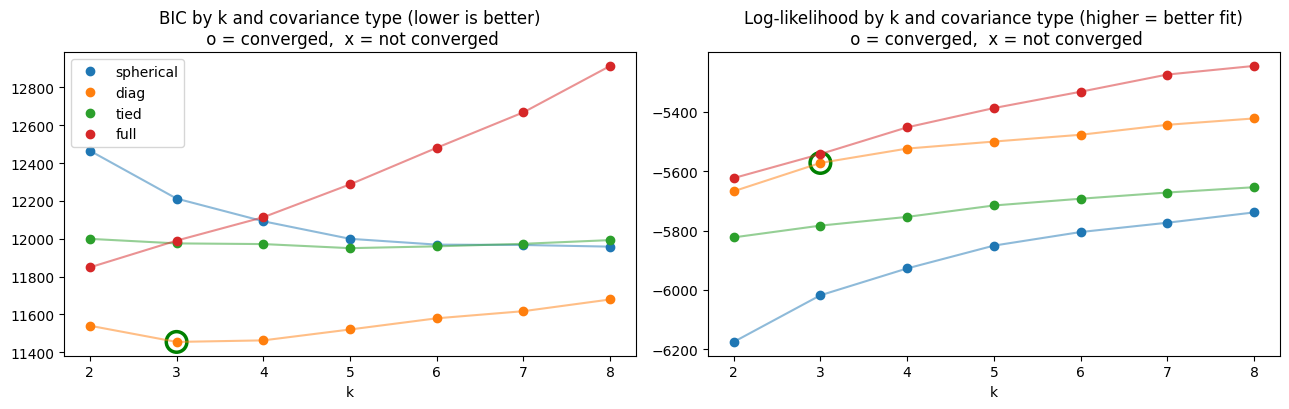

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
cols_plot = [('bic', 'BIC', 'lower is better'), ('log_likelihood', 'Log-likelihood', 'higher = better fit')]
for ci, cov in enumerate(COV_TYPES):
    sub_c = results_df[results_df['covariance_type'] == cov]
    for ax, (col, _, _) in zip(axes, cols_plot):
        ax.plot(sub_c['k'], sub_c[col], '-', alpha=0.5, color=f'C{ci}')
        ok = sub_c[sub_c['converged']]; bad = sub_c[~sub_c['converged']]
        ax.plot(ok['k'], ok[col], 'o', color=f'C{ci}', label=cov)
        ax.plot(bad['k'], bad[col], 'x', color=f'C{ci}', ms=8, mew=2)
for ax, (_, name, note) in zip(axes, cols_plot):
    ax.set_title(f'{name} by k and covariance type ({note})\n o = converged,  x = not converged')
    ax.set_xlabel('k'); ax.set_xticks(list(K_RANGE))
axes[0].legend()
axes[0].scatter([best_row['k']], [best_row['bic']], s=220, facecolors='none', edgecolors='green', linewidths=2.5)
axes[1].scatter([best_row['k']], [best_row['log_likelihood']], s=220, facecolors='none', edgecolors='green', linewidths=2.5)
plt.tight_layout(); plt.show()

In [24]:
chosen_row = best_row

print("Selection rule for k (and covariance type):")
print("  CHECK 1 - BIC minimum        (model complexity check)")
print("  CHECK 2 - log-likelihood     (EM convergence check)")
print(f"\nCHOSEN: k={int(chosen_row['k'])}, '{chosen_row['covariance_type']}'   "
      f"(lowest BIC among converged fits: BIC {chosen_row['bic']:.0f}, "
      f"log-likelihood {chosen_row['log_likelihood']:.0f}, converged in {int(chosen_row['n_iter'])} iterations)")

Selection rule for k (and covariance type):
  CHECK 1 - BIC minimum        (model complexity check)
  CHECK 2 - log-likelihood     (EM convergence check)

CHOSEN: k=3, 'diag'   (lowest BIC among converged fits: BIC 11454, log-likelihood -5573, converged in 20 iterations)


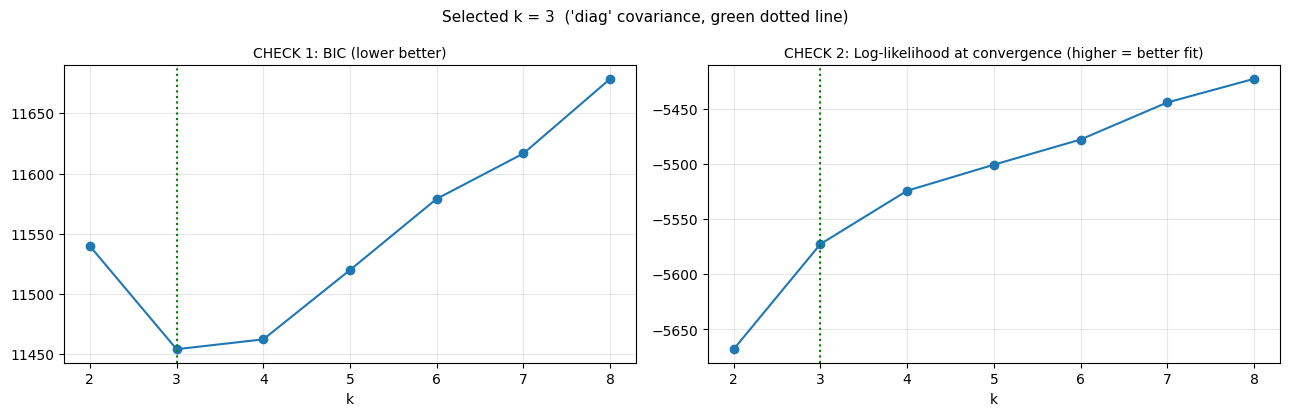

In [25]:
sel_k, sel_cov = int(chosen_row['k']), chosen_row['covariance_type']
sub = results_df[(results_df['covariance_type'] == sel_cov) & results_df['converged']].sort_values('k')

specs = [('bic', 'CHECK 1: BIC (lower better)'),
         ('log_likelihood', 'CHECK 2: Log-likelihood at convergence (higher = better fit)')]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (col, title) in zip(axes, specs):
    ax.plot(sub['k'], sub[col], marker='o', color='C0')
    ax.axvline(sel_k, color='green', ls=':', lw=1.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('k')
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
fig.suptitle(f"Selected k = {sel_k}  ('{sel_cov}' covariance, green dotted line)", fontsize=11)
plt.tight_layout()
plt.show()

In [26]:
best_k, best_covariance_type = sel_k, sel_cov
print(f"Selected k = {best_k}, covariance_type = '{best_covariance_type}'")

gmm = make_gmm(best_k, best_covariance_type)
gmm_clusters = pd.Series(gmm.fit_predict(X), index=X_clean.index, name='gmm_cluster')
print("Converged:", gmm.converged_)
gmm_clusters.value_counts().sort_index()

Selected k = 3, covariance_type = 'diag'
Converged: True


,count
gmm_cluster,
0,41
1,86
2,121


In [27]:
log_lik = gmm.score(X) * X.shape[0]

M = consensus_matrix(X, best_k, best_covariance_type)
mk = cluster_consensus(M, gmm_clusters.values, n_clusters=best_k)

print(f"BIC: {gmm.bic(X):.2f}  (lower is better)")
print(f"Log-likelihood: {log_lik:.2f}  (converged: {gmm.converged_}, {gmm.n_iter_} iterations)")
print(f"Cluster consensus (mean): {np.nanmean(mk):.4f}  (least stable cluster {np.nanmin(mk):.3f}; 1 = perfectly stable)")

BIC: 11454.13  (lower is better)
Log-likelihood: -5572.69  (converged: True, 20 iterations)
Cluster consensus (mean): 0.9611  (least stable cluster 0.959; 1 = perfectly stable)


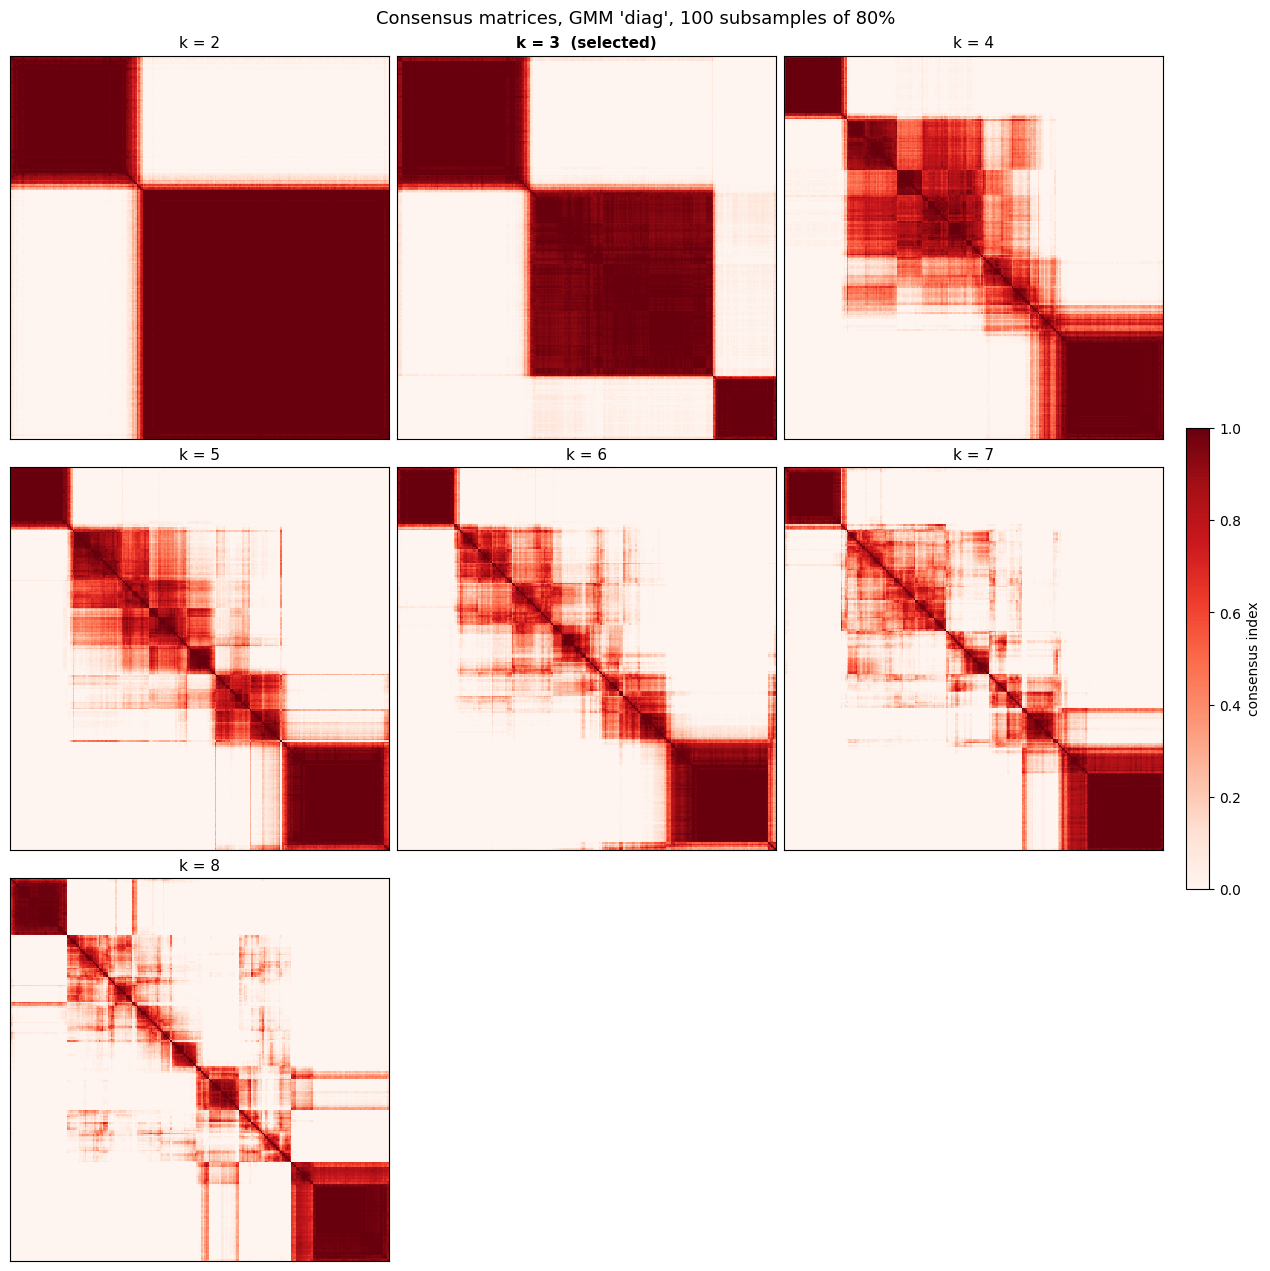

In [28]:
ks_all = list(K_RANGE)
ncols = 3; nrows = int(np.ceil(len(ks_all) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.2 * nrows), squeeze=False, constrained_layout=True)
for ax, kk in zip(axes.flat, ks_all):
    Mk = consensus_matrix(X, kk, best_covariance_type)
    Dk = squareform(1 - Mk, checks=False)
    order_k = leaves_list(optimal_leaf_ordering(linkage(Dk, method="average"), Dk))
    im = ax.imshow(Mk[np.ix_(order_k, order_k)], cmap="Reds", vmin=0, vmax=1, interpolation="nearest", aspect="auto")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"k = {kk}" + ("  (selected)" if kk == best_k else ""), fontsize=11,
                 fontweight="bold" if kk == best_k else "normal")
for ax in axes.flat[len(ks_all):]:
    ax.axis("off")
fig.suptitle(f"Consensus matrices, GMM '{best_covariance_type}', {N_SUBSAMPLES} subsamples of {SUBSAMPLE_FRAC:.0%}", fontsize=13)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02, label="consensus index")
plt.show()

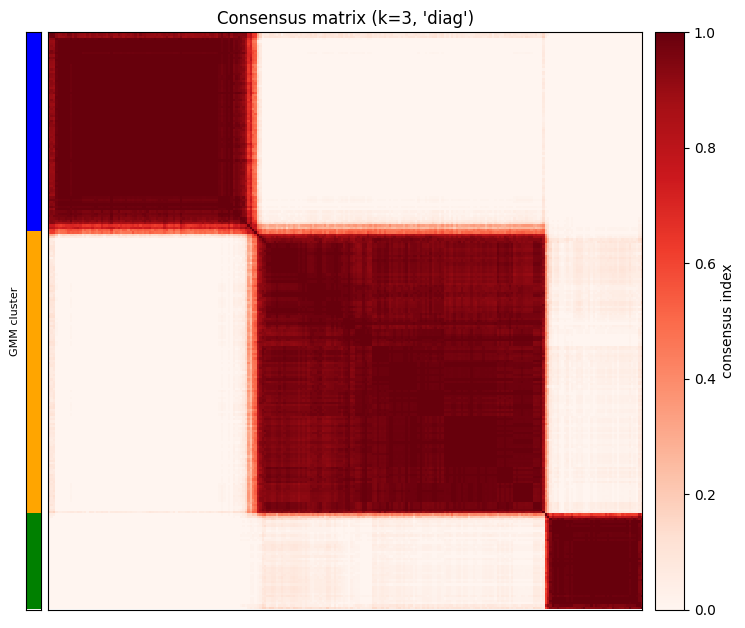

Cluster consensus m(k)  (1 = perfectly stable):
  Cluster 0 (n=41): 0.963
  Cluster 1 (n=86): 0.961
  Cluster 2 (n=121): 0.959


In [29]:
final_labels = gmm_clusters.values
Dm = squareform(1 - M, checks=False)
order = leaves_list(optimal_leaf_ordering(linkage(Dm, method="average"), Dm))
side_colors = ListedColormap(["green", "blue", "orange", "red", "purple", "brown", "pink", "grey"][:best_k])

fig, (ax_bar, ax_hm) = plt.subplots(1, 2, figsize=(8.5, 7.5), gridspec_kw={"width_ratios": [1, 40], "wspace": 0.02})
im = ax_hm.imshow(M[np.ix_(order, order)], cmap="Reds", vmin=0, vmax=1, interpolation="nearest", aspect="auto")
ax_bar.imshow(final_labels[order][:, None], cmap=side_colors, vmin=0, vmax=max(best_k - 1, 1),
              interpolation="nearest", aspect="auto")
for ax in (ax_bar, ax_hm):
    ax.set_xticks([]); ax.set_yticks([])
ax_bar.set_ylabel("GMM cluster", fontsize=8)
ax_hm.set_title(f"Consensus matrix (k={best_k}, '{best_covariance_type}')")
fig.colorbar(im, ax=ax_hm, fraction=0.046, pad=0.02, label="consensus index")
plt.show()

print("Cluster consensus m(k)  (1 = perfectly stable):")
for c in range(best_k):
    print(f"  Cluster {c} (n={int((final_labels == c).sum())}): {mk[c]:.3f}")

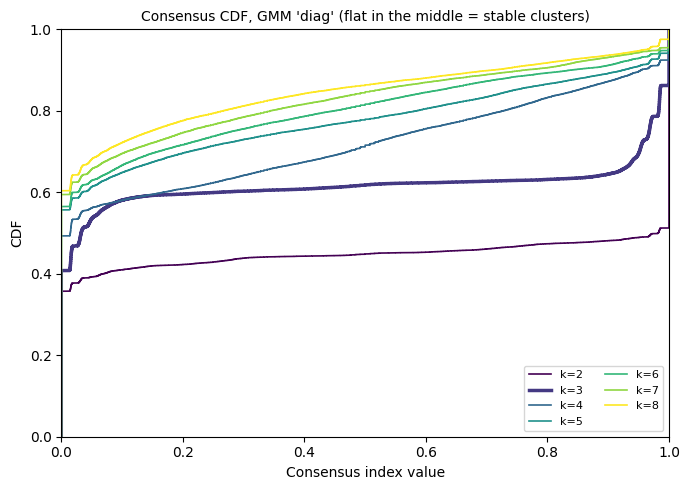

In [30]:

fig, ax = plt.subplots(figsize=(7, 5))
cmap = plt.get_cmap("viridis", len(K_RANGE))

for i, kk in enumerate(K_RANGE):
    Mk = consensus_matrix(X, kk, best_covariance_type)
    vals = np.sort(Mk[np.triu_indices(Mk.shape[0], 1)])
    cdf_vals = np.arange(1, len(vals) + 1) / len(vals)
    ax.step(vals, cdf_vals, where="post", color=cmap(i),
            lw=2.5 if kk == best_k else 1.2, label=f"k={kk}")

ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Consensus index value")
ax.set_ylabel("CDF")
ax.set_title(f"Consensus CDF, GMM '{best_covariance_type}' (flat in the middle = stable clusters)", fontsize=10)
ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout()
plt.show()

In [31]:

summ = []
for kk in K_RANGE:
    Mk = consensus_matrix(X, kk, best_covariance_type)
    g = make_gmm(kk, best_covariance_type)
    lab_k = g.fit_predict(X)
    cc = cluster_consensus(Mk, lab_k, n_clusters=kk)
    sizes = np.bincount(lab_k, minlength=kk)
    summ.append({'k': kk, 'BIC': g.bic(X), 'log-likelihood': g.score(X) * X.shape[0],
                 'mean cluster consensus': np.nanmean(cc), 'min cluster consensus': np.nanmin(cc),
                 'smallest cluster': int(sizes.min())})
summary_df = pd.DataFrame(summ).set_index('k')
print(f"BIC, log-likelihood and stability by k  (covariance = '{best_covariance_type}')")
display(summary_df.round(3).style.format({'BIC': '{:.0f}', 'log-likelihood': '{:.0f}', 'smallest cluster': '{:.0f}'})
        .background_gradient(cmap='Reds', vmin=0, vmax=1, subset=['mean cluster consensus', 'min cluster consensus']))

cols = [f"Cluster {c}" for c in range(max(K_RANGE))]
cc_rows, size_rows = {}, {}
for kk in K_RANGE:
    lab_k = make_gmm(kk, best_covariance_type).fit_predict(X)
    cc_rows[kk] = cluster_consensus(consensus_matrix(X, kk, best_covariance_type), lab_k, n_clusters=kk)
    size_rows[kk] = np.bincount(lab_k, minlength=kk)
cluster_consensus_table = pd.DataFrame([list(v) + [np.nan] * (len(cols) - len(v)) for v in cc_rows.values()],
                                       index=pd.Index(list(cc_rows), name="k"), columns=cols)
cluster_size_table = pd.DataFrame([list(v) + [np.nan] * (len(cols) - len(v)) for v in size_rows.values()],
                                  index=pd.Index(list(size_rows), name="k"), columns=cols)
print("Cluster consensus per cluster (blank = no such cluster at this k)")
display(cluster_consensus_table.round(3).style.format("{:.3f}", na_rep="")
        .background_gradient(cmap="Reds", vmin=0, vmax=1, subset=cols))
print("Cluster sizes (number of stocks)")
display(cluster_size_table.style.format("{:.0f}", na_rep=""))

BIC, log-likelihood and stability by k  (covariance = 'diag')


,BIC,log-likelihood,mean cluster consensus,min cluster consensus,smallest cluster
k,,,,,
2,11540,-5668,0.973000,0.958000,84
3,11454,-5573,0.961000,0.959000,41
4,11462,-5524,0.817000,0.599000,41
5,11520,-5501,0.822000,0.652000,16
6,11579,-5478,0.704000,0.495000,29
7,11617,-5444,0.667000,0.370000,10
8,11679,-5423,0.702000,0.349000,9


Cluster consensus per cluster (blank = no such cluster at this k)


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7
k,,,,,,,,
2,0.989,0.958,,,,,,
3,0.963,0.961,0.959,,,,,
4,0.599,0.933,0.979,0.759,,,,
5,0.875,0.715,0.919,0.952,0.652,,,
6,0.972,0.902,0.655,0.548,0.495,0.649,,
7,0.702,0.525,0.932,0.491,0.661,0.370,0.989,
8,0.747,0.942,0.349,0.822,0.548,0.712,0.983,0.515


Cluster sizes (number of stocks)


,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4,Cluster 5,Cluster 6,Cluster 7
k,,,,,,,,
2,164,84,,,,,,
3,41,86,121,,,,,
4,47,41,69,91,,,,
5,16,45,41,68,78,,,
6,62,40,29,54,31,32,,
7,10,39,38,26,12,72,51,
8,9,37,61,16,41,13,50,21


In [32]:
probabilities = gmm.predict_proba(X)
maximum_probability = probabilities.max(axis=1)

uncertainty = pd.DataFrame({
    'cluster': gmm_clusters,
    'membership_probability': maximum_probability,
    'uncertain': maximum_probability < 0.70
}, index=X_clean.index)

print(uncertainty.sort_values('membership_probability').head(15))
print("Number of uncertain assignments (max posterior < 0.70):", int(uncertainty['uncertain'].sum()))

        cluster  membership_probability  uncertain
Ticker                                            
PPET.L        1                0.519525       True
ASHM.L        2                0.523314       True
JTC.L         1                0.563666       True
WKP.L         0                0.572103       True
SEIT.L        0                0.654065       True
PCGH.L        1                0.677706       True
HANA.L        1                0.702452      False
BOY.L         2                0.784008      False
N91.L         1                0.789424      False
MUT.L         1                0.796748      False
VCT.L         0                0.816649      False
GFRD.L        1                0.817848      False
BWY.L         2                0.844045      False
EWG.L         2                0.852052      False
BPT.L         0                0.855741      False
Number of uncertain assignments (max posterior < 0.70): 6


In [33]:
for c in sorted(gmm_clusters.unique()):
    tickers = sorted(gmm_clusters[gmm_clusters == c].index)
    print(f"Cluster {c} (n={len(tickers)}):")
    print(textwrap.fill(', '.join(tickers), width=100))
    print()

Cluster 0 (n=41):
AIE.L, ALFA.L, AML.L, BCG.L, BME.L, BPT.L, BREE.L, DATA.L, DNLM.L, DOM.L, FGP.L, FGT.L, GAMA.L,
GEN.L, GRI.L, HAS.L, HFG.L, HGT.L, HIK.L, HWG.L, MEGP.L, MNDI.L, MONY.L, PAG.L, PAGE.L, PETS.L,
RMV.L, RNK.L, SEIT.L, SMWH.L, TEP.L, TRIG.L, TRN.L, TW.L, UKW.L, UTG.L, VCT.L, VTY.L, WKP.L, WPP.L,
XPS.L

Cluster 1 (n=86):
AAS.L, AEP.L, APN.L, ATR.L, ATT.L, ATYM.L, BBY.L, BHMG.L, BNKR.L, BPCR.L, BRWM.L, CGT.L, CKN.L,
CMCX.L, CORD.L, COST.L, CSN.L, CTY.L, CWR.L, DRX.L, EMG.L, EWI.L, FEML.L, FSV.L, GFRD.L, GROW.L,
GSCT.L, HANA.L, HFEL.L, HILS.L, HMSO.L, HOC.L, HRI.L, HTG.L, HTWS.L, HVPE.L, IAD.L, INCH.L, INPP.L,
IPF.L, JAM.L, JCH.L, JEDT.L, JEGI.L, JEMI.L, JFJ.L, JMGI.L, JTC.L, JUP.L, KLR.L, LWDB.L, MNKS.L,
MNTN.L, MRCH.L, MTO.L, MUT.L, MYI.L, N91.L, OXIG.L, PAF.L, PCGH.L, PHI.L, PIN.L, PINT.L, PLUS.L,
PNL.L, PPET.L, QLT.L, RCP.L, RICA.L, RSW.L, RTW.L, SAGA.L, SDP.L, SNR.L, SOI.L, SRP.L, SSIT.L,
TEM.L, TMPL.L, UEM.L, USA.L, VSVS.L, WOSG.L, XPP.L, ZIG.L

Cluster 2 (n=121):
3IN.L

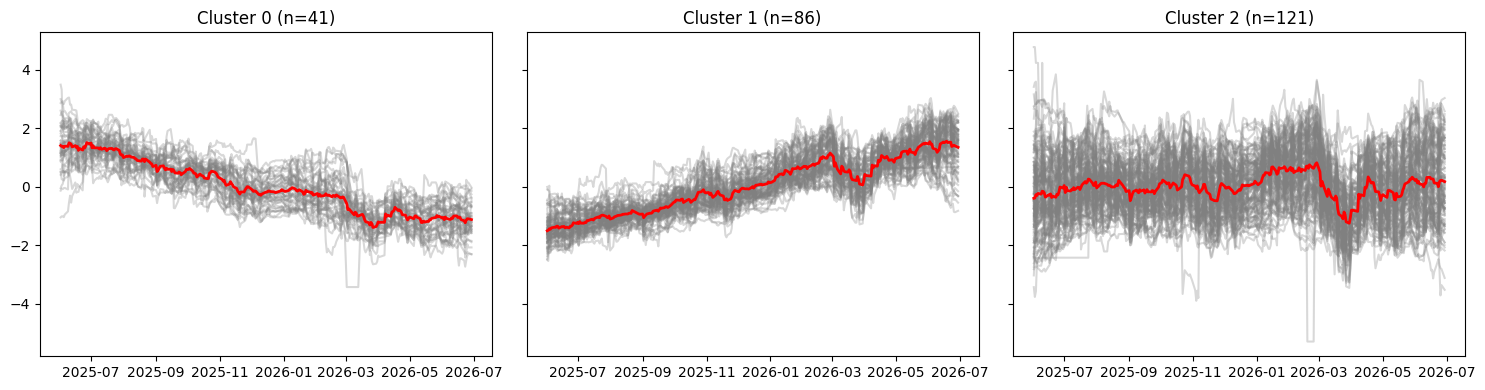

In [34]:
unique_clusters = sorted(gmm_clusters.unique())
fig, axes = plt.subplots(1, len(unique_clusters), figsize=(5 * len(unique_clusters), 4), sharey=True, squeeze=False)
for ax, c in zip(axes[0], unique_clusters):
    members = gmm_clusters[gmm_clusters == c].index
    for t in members:
        ax.plot(X_clean.columns, X_clean.loc[t], alpha=0.3, color='gray')
    ax.plot(X_clean.columns, X_clean.loc[members].mean(axis=0), color='red', linewidth=2)
    ax.set_title(f'Cluster {c} (n={len(members)})')
plt.tight_layout(); plt.show()